# Crea tu propio entorno personalizado con Gymnasium
### Guía paso a paso — adaptada para Google Colab

**Basado en:** https://gymnasium.farama.org/tutorials/gymnasium_basics/environment_creation/

**Modificador y Ejecutor:** Carlos Francisco Montoya Urzua

---

<a id='instalacion'></a>
## 1. Instalación

In [1]:
!pip install gymnasium pygame matplotlib --quiet

In [2]:
# Imports que usaremos a lo largo del notebook
from enum import Enum
import numpy as np
import pygame
import gymnasium as gym
from gymnasium import spaces
import matplotlib.pyplot as plt

print(f"Gymnasium versión: {gym.__version__}")

pygame 2.6.1 (SDL 2.28.4, Python 3.12.13)
Hello from the pygame community. https://www.pygame.org/contribute.html
Gymnasium versión: 1.3.0


<a id='subclase'></a>
## 2. ¿Qué significa subclasificar `gymnasium.Env`?

Todos los entornos de Gymnasium heredan de la clase base `gym.Env`. Esto significa que tu entorno personalizado **debe implementar estos métodos obligatorios**:

| Método | ¿Qué hace? |
|--------|------------|
| `__init__` | Define el espacio de observaciones, el espacio de acciones y variables internas. |
| `reset()` | Reinicia el entorno y devuelve el estado inicial. |
| `step(action)` | Aplica una acción y devuelve `(obs, reward, terminated, truncated, info)`. |
| `render()` | Genera una visualización del estado actual (opcional pero muy útil). |
| `close()` | Libera recursos (ventanas, archivos, etc.). |

Construiremos cada método por separado para entenderlo bien, y al final los uniremos en una sola clase.

<a id='init'></a>
## 3. Paso 1 — Declaración e Inicialización (`__init__`)

El `__init__` define **todo lo que el entorno necesita saber antes de empezar**:

- El tamaño de la cuadrícula (`size`).
- El **espacio de observaciones**: qué información recibe el agente. Aquí le damos la posición del agente y del objetivo, cada una como un par `[fila, columna]`.
- El **espacio de acciones**: cuántas acciones puede tomar el agente. Usamos `Discrete(4)` para las 4 direcciones.
- Un diccionario que mapea cada número de acción a un vector de dirección.
- Variables de renderizado (ventana de Pygame).

También definimos el **enum `Actions`** para que el código sea más legible:

In [3]:
class Actions(Enum):
    RIGHT = 0  # Derecha
    UP    = 1  # Arriba
    LEFT  = 2  # Izquierda
    DOWN  = 3  # Abajo

# Probamos que funciona
print("Acción 0 →", Actions(0).name)
print("Acción 1 →", Actions(1).name)
print("Acción 2 →", Actions(2).name)
print("Acción 3 →", Actions(3).name)

Acción 0 → RIGHT
Acción 1 → UP
Acción 2 → LEFT
Acción 3 → DOWN


Ahora veamos el `__init__` con comentarios detallados en cada línea:

In [11]:
# ──────────────────────────────────────────────────────────────────
#  PASO 1: __init__  (solo para leer y entender — la clase completa
#  está en la Sección 9)
# ──────────────────────────────────────────────────────────────────

def __init__(self, render_mode=None, size=5):
    self.size = size              # Tamaño del lado de la cuadrícula (5 → 5×5)
    self.window_size = 512        # Tamaño en píxeles de la ventana de Pygame

    # ── Espacio de OBSERVACIONES ──────────────────────────────────
    # El agente observa su propia posición y la posición del objetivo.
    # Cada posición es un vector [fila, columna] con valores en {0,...,size-1}.
    # Usamos un diccionario con dos claves: "agent" y "target".
    self.observation_space = spaces.Dict(
        {
            "agent":  spaces.Box(0, size - 1, shape=(2,), dtype=int),
            "target": spaces.Box(0, size - 1, shape=(2,), dtype=int),
        }
    )

    # Posiciones internas (se inicializarán en reset())
    self._agent_location  = np.array([-1, -1], dtype=int)
    self._target_location = np.array([-1, -1], dtype=int)

    # ── Espacio de ACCIONES ───────────────────────────────────────
    # 4 acciones posibles: derecha (0), arriba (1), izquierda (2), abajo (3)
    self.action_space = spaces.Discrete(4)

    # Mapeo de número de acción → vector de desplazamiento [Δfila, Δcol]
    # Nota: fila 0 está arriba; ir "arriba" resta 1 a la fila.
    self._action_to_direction = {
        Actions.RIGHT.value: np.array([ 0,  1]),   # → columna +1
        Actions.UP.value:    np.array([-1,  0]),   # ↑ fila -1
        Actions.LEFT.value:  np.array([ 0, -1]),   # ← columna -1
        Actions.DOWN.value:  np.array([ 1,  0]),   # ↓ fila +1
    }

    # ── Configuración de RENDERIZADO ──────────────────────────────
    # render_mode puede ser "human" (ventana Pygame) o "rgb_array" (array NumPy)
    assert render_mode is None or render_mode in ["human", "rgb_array"]
    self.render_mode = render_mode
    self.window = None   # Se crea la primera vez que se llama a render en modo "human"
    self.clock  = None   # Reloj para controlar FPS

print("__init__ definido")

__init__ definido


<a id='obs'></a>
## 4. Paso 2 — Obtener Observaciones e Información Auxiliar

Definimos dos métodos **privados** (con prefijo `_`) que serán llamados por `reset()` y `step()` para no repetir código:

- `_get_obs()` — devuelve el **diccionario de observación** con la posición del agente y del objetivo.
- `_get_info()` — devuelve información **auxiliar** (no usada para aprender, pero útil para depurar). Aquí devolvemos la distancia Manhattan entre agente y objetivo.

In [12]:
# ──────────────────────────────────────────────────────────────────
#  PASO 2: _get_obs y _get_info  (solo para leer y entender)
# ──────────────────────────────────────────────────────────────────

def _get_obs(self):
    # Devuelve un diccionario con las posiciones actuales
    # Ejemplo: {"agent": [1, 0], "target": [4, 3]}
    return {"agent": self._agent_location, "target": self._target_location}


def _get_info(self):
    # Distancia Manhattan = |Δfila| + |Δcol|
    # Es la mínima cantidad de pasos para llegar al objetivo sin paredes.
    return {
        "distance": np.linalg.norm(
            self._agent_location - self._target_location, ord=1
        )
    }

# ── Demostración rápida ───────────────────────────────────────────
# Simulamos lo que devolvería _get_info si el agente está en [1,0] y el objetivo en [4,3]
_agent_location  = np.array([1, 0])
_target_location = np.array([4, 3])
dist = np.linalg.norm(_agent_location - _target_location, ord=1)
print(f"Agente en {_agent_location}, objetivo en {_target_location}")
print(f"Distancia Manhattan = |4-1| + |3-0| = {dist:.0f} pasos")

Agente en [1 0], objetivo en [4 3]
Distancia Manhattan = |4-1| + |3-0| = 6 pasos


<a id='reset'></a>
## 5. Paso 3 — Reiniciar el Entorno (`reset`)

`reset()` se llama al **inicio de cada episodio**. Debe:

1. Llamar a `super().reset(seed=seed)` para inicializar el generador de números aleatorios interno.
2. Colocar al agente en una posición aleatoria.
3. Colocar al objetivo en otra posición aleatoria **distinta** a la del agente.
4. Devolver `(observación_inicial, info_inicial)`.

In [13]:
# ──────────────────────────────────────────────────────────────────
#  PASO 3: reset  (solo para leer y entender)
# ──────────────────────────────────────────────────────────────────

def reset(self, seed=None, options=None):
    # Necesario para que gymnasium inicialice self.np_random correctamente
    super().reset(seed=seed)

    # Posición aleatoria del agente dentro de la cuadrícula [0, size)
    self._agent_location = self.np_random.integers(0, self.size, size=2, dtype=int)

    # Posición aleatoria del objetivo — repetimos hasta que no coincida con el agente
    self._target_location = self._agent_location.copy()
    while np.array_equal(self._target_location, self._agent_location):
        self._target_location = self.np_random.integers(0, self.size, size=2, dtype=int)

    observation = self._get_obs()
    info = self._get_info()

    # Si estamos en modo "human", renderizamos el estado inicial
    if self.render_mode == "human":
        self._render_frame()

    return observation, info

print("Reset definido")

Reset definido


<a id='step'></a>
## 6. Paso 4 — Ejecutar un Paso (`step`)

`step(action)` es **el corazón del entorno**. Recibe un número de acción (0–3), aplica el movimiento y devuelve:

| Valor devuelto | Tipo | Descripción |
|----------------|------|-------------|
| `observation` | dict | Nueva posición del agente y del objetivo |
| `reward` | float | 1 si llegó al objetivo, 0 si no |
| `terminated` | bool | `True` si el episodio terminó (agente llegó al objetivo) |
| `truncated` | bool | `False` aquí (se volvería `True` con un wrapper de límite de pasos) |
| `info` | dict | Distancia Manhattan actual |

Usamos `np.clip` para que el agente **no salga de la cuadrícula**.

In [14]:
# ──────────────────────────────────────────────────────────────────
#  PASO 4: step  (solo para leer y entender)
# ──────────────────────────────────────────────────────────────────

def step(self, action):
    # Convertimos el número de acción en un vector de desplazamiento
    direction = self._action_to_direction[action]

    # Movemos al agente y recortamos para que no salga de la cuadrícula
    self._agent_location = np.clip(
        self._agent_location + direction,
        0,              # mínimo: celda 0
        self.size - 1   # máximo: celda size-1
    )

    # El episodio termina cuando el agente llega al objetivo
    terminated = np.array_equal(self._agent_location, self._target_location)

    # Recompensa binaria: 1 al llegar, 0 en cualquier otro paso
    reward = 1 if terminated else 0

    observation = self._get_obs()
    info = self._get_info()

    if self.render_mode == "human":
        self._render_frame()

    # truncated=False porque no tenemos límite de pasos aquí
    return observation, reward, terminated, False, info

# ── Demostración rápida ───────────────────────────────────────────
# Simulamos el resultado de clip para no salir de la cuadrícula
size = 5
agent = np.array([0, 0])   # Esquina superior izquierda
move_left = np.array([0, -1])
resultado = np.clip(agent + move_left, 0, size - 1)
print(f"Agente en {agent}, intenta moverse a la izquierda {move_left}")
print(f"Resultado tras np.clip: {resultado}  ← se queda en la pared")

Agente en [0 0], intenta moverse a la izquierda [ 0 -1]
Resultado tras np.clip: [0 0]  ← se queda en la pared


<a id='render'></a>
## 7. Paso 5 — Renderizado Visual (`render` y `_render_frame`)

El renderizado usa **Pygame** para dibujar:
- Un **cuadrado rojo** en la posición del objetivo.
- Un **círculo azul** en la posición del agente.
- **Líneas de cuadrícula** negras.

Hay dos modos:
- `"human"` → abre una ventana de Pygame en tiempo real.
- `"rgb_array"` → devuelve un array NumPy con la imagen (ideal para Colab y para guardar GIFs).

> **Nota Colab:** el modo `"human"` no funciona en Colab porque no hay pantalla. Usaremos `"rgb_array"` y mostraremos las imágenes con Matplotlib.

In [15]:
# ──────────────────────────────────────────────────────────────────
#  PASO 5: render y _render_frame  (solo para leer y entender)
# ──────────────────────────────────────────────────────────────────

def render(self):
    # En modo "rgb_array" devolvemos la imagen como array NumPy
    if self.render_mode == "rgb_array":
        return self._render_frame()


def _render_frame(self):
    # Inicializamos Pygame la primera vez en modo "human"
    if self.window is None and self.render_mode == "human":
        pygame.init()
        pygame.display.init()
        self.window = pygame.display.set_mode((self.window_size, self.window_size))
    if self.clock is None and self.render_mode == "human":
        self.clock = pygame.time.Clock()

    # Creamos un lienzo (canvas) blanco
    canvas = pygame.Surface((self.window_size, self.window_size))
    canvas.fill((255, 255, 255))  # Fondo blanco

    # Tamaño en píxeles de cada celda de la cuadrícula
    pix_square_size = self.window_size / self.size

    # ── Dibujamos el OBJETIVO (cuadrado rojo) ─────────────────────
    # Nota: Pygame usa (x, y) = (columna, fila), por eso invertimos con [::-1]
    pygame.draw.rect(
        canvas,
        (255, 0, 0),   # Color rojo
        pygame.Rect(
            pix_square_size * self._target_location[::-1],   # esquina superior izquierda
            (pix_square_size, pix_square_size),              # tamaño del cuadrado
        ),
    )

    # ── Dibujamos el AGENTE (círculo azul) ────────────────────────
    pygame.draw.circle(
        canvas,
        (0, 0, 255),   # Color azul
        (self._agent_location[::-1] + 0.5) * pix_square_size,  # centro del círculo
        pix_square_size / 3,    # radio del círculo
    )

    # ── Dibujamos las LÍNEAS DE CUADRÍCULA ────────────────────────
    for x in range(self.size + 1):
        # Líneas horizontales
        pygame.draw.line(canvas, 0, (0, pix_square_size * x),
                         (self.window_size, pix_square_size * x), width=3)
        # Líneas verticales
        pygame.draw.line(canvas, 0, (pix_square_size * x, 0),
                         (pix_square_size * x, self.window_size), width=3)

    # ── Volcamos al modo correspondiente ─────────────────────────
    if self.render_mode == "human":
        self.window.blit(canvas, canvas.get_rect())
        pygame.event.pump()
        pygame.display.update()
        self.clock.tick(self.metadata["render_fps"])
    else:  # "rgb_array"
        # Convertimos el Surface de Pygame a array NumPy (H, W, 3)
        return np.transpose(
            np.array(pygame.surfarray.pixels3d(canvas)), axes=(1, 0, 2)
        )

print("Render y _render_frame definidos")

Render y _render_frame definidos


<a id='close'></a>
## 8. Paso 6 — Cerrar Recursos (`close`)

`close()` libera la ventana de Pygame si fue abierta. Es buena práctica llamarlo siempre al terminar de usar el entorno.

In [16]:
# ──────────────────────────────────────────────────────────────────
#  PASO 6: close  (solo para leer y entender)
# ──────────────────────────────────────────────────────────────────

def close(self):
    # Solo cerramos Pygame si la ventana fue abierta
    if self.window is not None:
        pygame.display.quit()
        pygame.quit()

print("Close definido")

Close definido


<a id='clase-completa'></a>
## 9. Clase Completa Unificada

Aquí juntamos todo en una sola celda. **Ejecuta esta celda** — es la que crea el entorno real que usaremos en las siguientes secciones.

In [17]:
from enum import Enum
import numpy as np
import pygame
import gymnasium as gym
from gymnasium import spaces


class Actions(Enum):
    RIGHT = 0
    UP    = 1
    LEFT  = 2
    DOWN  = 3


class GridWorldEnv(gym.Env):
    """Entorno GridWorld personalizado basado en el tutorial oficial de Gymnasium.

    El agente (círculo azul) debe llegar al objetivo (cuadrado rojo)
    en una cuadrícula de tamaño `size × size`.
    """

    # Metadatos: modos de renderizado soportados y FPS
    metadata = {"render_modes": ["human", "rgb_array"], "render_fps": 4}

    # ── __init__ ──────────────────────────────────────────────────
    def __init__(self, render_mode=None, size=5):
        self.size = size
        self.window_size = 512

        self.observation_space = spaces.Dict(
            {
                "agent":  spaces.Box(0, size - 1, shape=(2,), dtype=int),
                "target": spaces.Box(0, size - 1, shape=(2,), dtype=int),
            }
        )
        self._agent_location  = np.array([-1, -1], dtype=int)
        self._target_location = np.array([-1, -1], dtype=int)

        self.action_space = spaces.Discrete(4)

        self._action_to_direction = {
            Actions.RIGHT.value: np.array([ 0,  1]),
            Actions.UP.value:    np.array([-1,  0]),
            Actions.LEFT.value:  np.array([ 0, -1]),
            Actions.DOWN.value:  np.array([ 1,  0]),
        }

        assert render_mode is None or render_mode in self.metadata["render_modes"]
        self.render_mode = render_mode
        self.window = None
        self.clock  = None

    # ── Métodos auxiliares ────────────────────────────────────────
    def _get_obs(self):
        return {"agent": self._agent_location, "target": self._target_location}

    def _get_info(self):
        return {
            "distance": np.linalg.norm(
                self._agent_location - self._target_location, ord=1
            )
        }

    # ── reset ─────────────────────────────────────────────────────
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self._agent_location = self.np_random.integers(0, self.size, size=2, dtype=int)

        self._target_location = self._agent_location.copy()
        while np.array_equal(self._target_location, self._agent_location):
            self._target_location = self.np_random.integers(
                0, self.size, size=2, dtype=int
            )

        observation = self._get_obs()
        info = self._get_info()

        if self.render_mode == "human":
            self._render_frame()

        return observation, info

    # ── step ──────────────────────────────────────────────────────
    def step(self, action):
        direction = self._action_to_direction[action]
        self._agent_location = np.clip(
            self._agent_location + direction, 0, self.size - 1
        )

        terminated = np.array_equal(self._agent_location, self._target_location)
        reward = 1 if terminated else 0

        observation = self._get_obs()
        info = self._get_info()

        if self.render_mode == "human":
            self._render_frame()

        return observation, reward, terminated, False, info

    # ── render ────────────────────────────────────────────────────
    def render(self):
        if self.render_mode == "rgb_array":
            return self._render_frame()

    def _render_frame(self):
        if self.window is None and self.render_mode == "human":
            pygame.init()
            pygame.display.init()
            self.window = pygame.display.set_mode(
                (self.window_size, self.window_size)
            )
        if self.clock is None and self.render_mode == "human":
            self.clock = pygame.time.Clock()

        canvas = pygame.Surface((self.window_size, self.window_size))
        canvas.fill((255, 255, 255))
        pix_square_size = self.window_size / self.size

        # Objetivo (rojo)
        pygame.draw.rect(
            canvas,
            (255, 0, 0),
            pygame.Rect(
                pix_square_size * self._target_location[::-1],
                (pix_square_size, pix_square_size),
            ),
        )
        # Agente (azul)
        pygame.draw.circle(
            canvas,
            (0, 0, 255),
            (self._agent_location[::-1] + 0.5) * pix_square_size,
            pix_square_size / 3,
        )
        # Líneas de cuadrícula
        for x in range(self.size + 1):
            pygame.draw.line(
                canvas, 0,
                (0, pix_square_size * x),
                (self.window_size, pix_square_size * x),
                width=3,
            )
            pygame.draw.line(
                canvas, 0,
                (pix_square_size * x, 0),
                (pix_square_size * x, self.window_size),
                width=3,
            )

        if self.render_mode == "human":
            self.window.blit(canvas, canvas.get_rect())
            pygame.event.pump()
            pygame.display.update()
            self.clock.tick(self.metadata["render_fps"])
        else:  # rgb_array
            return np.transpose(
                np.array(pygame.surfarray.pixels3d(canvas)), axes=(1, 0, 2)
            )

    # ── close ─────────────────────────────────────────────────────
    def close(self):
        if self.window is not None:
            pygame.display.quit()
            pygame.quit()


print("Clase GridWorldEnv definida correctamente")

Clase GridWorldEnv definida correctamente


<a id='registro'></a>
## 10. Registrar el Entorno en Gymnasium

Registrar el entorno permite crearlo con `gym.make('nombre-del-entorno')` en lugar de instanciarlo directamente. Esto también añade automáticamente un **wrapper de límite de pasos** (`TimeLimit`) si especificamos `max_episode_steps`.

Como en Colab no tenemos un paquete instalable, registramos manualmente:

In [28]:
from gymnasium.envs.registration import register

# Registramos el entorno con un ID único
# max_episode_steps=300 añade un TimeLimit wrapper: el episodio termina
# si el agente no llega al objetivo en 300 pasos.
register(
    id="GridWorld-v0",
    entry_point=lambda **kwargs: GridWorldEnv(**kwargs),  # función que crea el entorno
    max_episode_steps=300,
)

print("Entorno 'GridWorld-v0' registrado")

# Ahora podemos crearlo con gym.make
env_registrado = gym.make("GridWorld-v0", render_mode="rgb_array")
obs, info = env_registrado.reset(seed=42)
print(f"\nObservación inicial: agente={obs['agent']}, objetivo={obs['target']}")
print(f"Info inicial: distancia Manhattan = {info['distance']:.0f}")
env_registrado.close()

  logger.warn(f"Overriding environment {new_spec.id} already in registry.")



Entorno 'GridWorld-v0' registrado

Observación inicial: agente=[0 3], objetivo=[3 2]
Info inicial: distancia Manhattan = 4


<a id='prueba'></a>
## 11. Probar el Entorno con Acciones Aleatorias

Antes de entrenar un agente inteligente, verificamos que el entorno funciona correctamente ejecutando un episodio con acciones completamente aleatorias.

In [29]:
# Creamos el entorno directamente (sin gym.make)
env = GridWorldEnv(render_mode="rgb_array", size=5)

obs, info = env.reset(seed=0)
print("=== Inicio del episodio ===")
print(f"  Agente en:  {obs['agent']}")
print(f"  Objetivo en: {obs['target']}")
print(f"  Distancia inicial: {info['distance']:.0f}")
print()

total_reward = 0
n_steps = 0
done = False
max_steps = 50  # Límite manual para este ejemplo

while not done and n_steps < max_steps:
    action = env.action_space.sample()           # Acción aleatoria (0–3)
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    total_reward += reward
    n_steps += 1

    nombre_accion = Actions(action).name
    print(f"  Paso {n_steps:2d} | Acción: {nombre_accion:<6} | "
          f"Agente: {obs['agent']} | Distancia: {info['distance']:.0f} | "
          f"Recompensa: {reward}")

    if done:
        print()
        print("¡El agente llegó al objetivo!")

if not done:
    print(f"\nNo llegó en {max_steps} pasos (acciones aleatorias).")

print(f"\nRecompensa total: {total_reward}  |  Pasos totales: {n_steps}")
env.close()

=== Inicio del episodio ===
  Agente en:  [4 3]
  Objetivo en: [2 1]
  Distancia inicial: 4

  Paso  1 | Acción: UP     | Agente: [3 3] | Distancia: 3 | Recompensa: 0
  Paso  2 | Acción: DOWN   | Agente: [4 3] | Distancia: 4 | Recompensa: 0
  Paso  3 | Acción: RIGHT  | Agente: [4 4] | Distancia: 5 | Recompensa: 0
  Paso  4 | Acción: UP     | Agente: [3 4] | Distancia: 4 | Recompensa: 0
  Paso  5 | Acción: LEFT   | Agente: [3 3] | Distancia: 3 | Recompensa: 0
  Paso  6 | Acción: UP     | Agente: [2 3] | Distancia: 2 | Recompensa: 0
  Paso  7 | Acción: LEFT   | Agente: [2 2] | Distancia: 1 | Recompensa: 0
  Paso  8 | Acción: LEFT   | Agente: [2 1] | Distancia: 0 | Recompensa: 1

¡El agente llegó al objetivo!

Recompensa total: 1  |  Pasos totales: 8


<a id='visualizar'></a>
## 12. Visualizar un Episodio Completo

Capturamos frames de cada paso y los mostramos como una tira de imágenes con Matplotlib. También guardamos un GIF animado.

Episodio terminado en 60 pasos. Frames capturados: 61


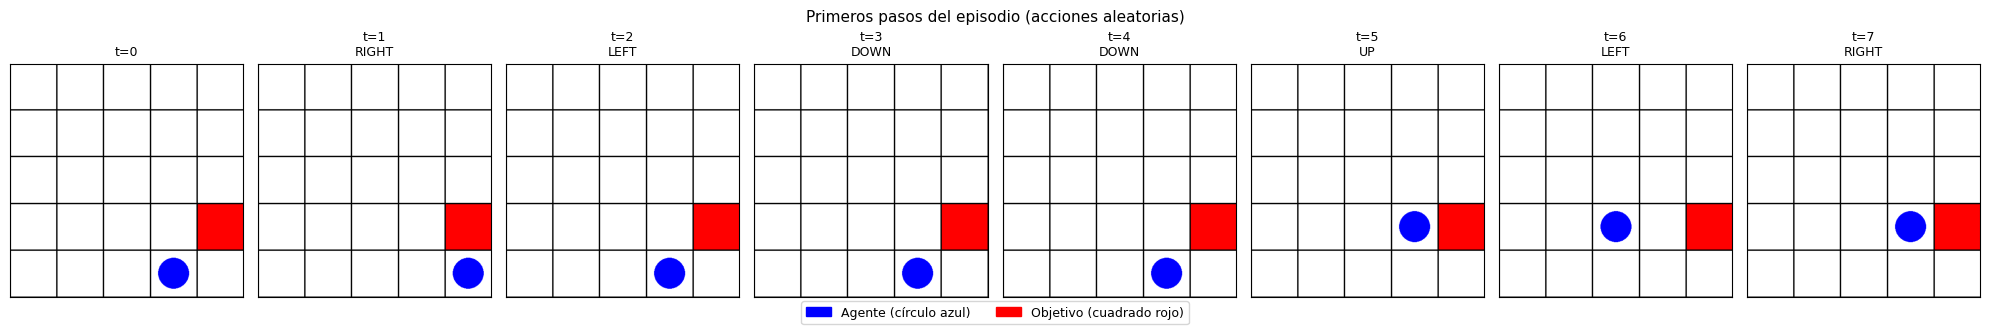

In [30]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

env = GridWorldEnv(render_mode="rgb_array", size=5)
obs, info = env.reset(seed=7)

frames = [env.render()]
acciones_tomadas = []

done = False
max_steps = 60
n_steps = 0

while not done and n_steps < max_steps:
    action = env.action_space.sample()
    obs, reward, terminated, truncated, info = env.step(action)
    done = terminated or truncated
    frames.append(env.render())
    acciones_tomadas.append(Actions(action).name)
    n_steps += 1

env.close()
print(f"Episodio terminado en {n_steps} pasos. Frames capturados: {len(frames)}")

# ── Mostramos los primeros 8 frames en una tira ───────────────────
n_mostrar = min(8, len(frames))
fig, axes = plt.subplots(1, n_mostrar, figsize=(2.5 * n_mostrar, 3))
if n_mostrar == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    ax.imshow(frames[i])
    ax.set_xticks([])
    ax.set_yticks([])
    titulo = f"t={i}"
    if i > 0:
        titulo += f"\n{acciones_tomadas[i-1]}"
    ax.set_title(titulo, fontsize=9)

agente_patch  = mpatches.Patch(color='blue',  label='Agente (círculo azul)')
objetivo_patch = mpatches.Patch(color='red',  label='Objetivo (cuadrado rojo)')
fig.legend(handles=[agente_patch, objetivo_patch], loc='lower center',
           ncol=2, fontsize=9, bbox_to_anchor=(0.5, -0.05))

plt.suptitle("Primeros pasos del episodio (acciones aleatorias)", fontsize=11, y=1.02)
plt.tight_layout()
plt.show()

In [31]:
# ── Guardamos un GIF del episodio completo ────────────────────────
try:
    from moviepy.editor import ImageSequenceClip
    clip = ImageSequenceClip(frames, fps=4)
    clip.write_gif("gridworld_episodio.gif", fps=4)
    print("GIF guardado como 'gridworld_episodio.gif'")
except ImportError:
    print("moviepy no está instalado. Ejecuta: !pip install moviepy --quiet")
    print("El entorno funciona correctamente de todas formas.")

MoviePy - Building file gridworld_episodio.gif with imageio.


GIF guardado como 'gridworld_episodio.gif'


<a id='wrappers'></a>
## 13. Usar Wrappers

El espacio de observaciones de `GridWorldEnv` es un **diccionario**, lo que no es compatible directamente con muchos algoritmos de RL. Los **wrappers** nos permiten modificar el comportamiento del entorno sin tocar su código.

### 13.1 `FlattenObservation` — Convertir el diccionario en un array 1D

In [23]:
from gymnasium.wrappers import FlattenObservation

# Sin wrapper: observación es un diccionario
env_raw = GridWorldEnv(size=5)
obs_raw, _ = env_raw.reset(seed=0)
print("Sin wrapper:")
print(f"  Tipo: {type(obs_raw)}")
print(f"  Valor: {obs_raw}")
env_raw.close()

print()

# Con FlattenObservation: observación es un array 1D [agent_row, agent_col, target_row, target_col]
env_flat = FlattenObservation(GridWorldEnv(size=5))
obs_flat, _ = env_flat.reset(seed=0)
print("Con FlattenObservation:")
print(f"  Tipo: {type(obs_flat)}")
print(f"  Valor: {obs_flat}   ← [agent_row, agent_col, target_row, target_col]")
print(f"  Shape: {obs_flat.shape}")
env_flat.close()

Sin wrapper:
  Tipo: <class 'dict'>
  Valor: {'agent': array([4, 3]), 'target': array([2, 1])}

Con FlattenObservation:
  Tipo: <class 'numpy.ndarray'>
  Valor: [4 3 2 1]   ← [agent_row, agent_col, target_row, target_col]
  Shape: (4,)


### 13.2 Wrapper personalizado — Posición relativa

En lugar de ver las posiciones absolutas, podemos dar al agente solo la **diferencia** entre su posición y la del objetivo. Esto hace que el problema sea más simple y generalizable.

In [24]:
class RelativePosition(gym.ObservationWrapper):
    """Wrapper que transforma la observación a posición relativa (objetivo - agente).

    En lugar de {"agent": [r1,c1], "target": [r2,c2]},
    devuelve un array [r2-r1, c2-c1].
    """

    def __init__(self, env):
        super().__init__(env)
        # El nuevo espacio de observación es un vector de 2 elementos
        # con valores en [-(size-1), +(size-1)]
        size = env.unwrapped.size
        self.observation_space = spaces.Box(
            low=-(size - 1),
            high=(size - 1),
            shape=(2,),
            dtype=int,
        )

    def observation(self, obs):
        # Devolvemos target - agent = vector hacia el objetivo
        return obs["target"] - obs["agent"]


# Probamos el wrapper
env_rel = RelativePosition(GridWorldEnv(size=5))
obs_rel, _ = env_rel.reset(seed=0)
print("Con RelativePosition:")
print(f"  Tipo: {type(obs_rel)}")
print(f"  Valor: {obs_rel}   ← [Δfila, Δcolumna] (objetivo - agente)")
print(f"  Interpretación: el objetivo está {obs_rel[0]:+d} filas y {obs_rel[1]:+d} columnas respecto al agente")
env_rel.close()

Con RelativePosition:
  Tipo: <class 'numpy.ndarray'>
  Valor: [-2 -2]   ← [Δfila, Δcolumna] (objetivo - agente)
  Interpretación: el objetivo está -2 filas y -2 columnas respecto al agente
